# Classroom Attendance Prediction

## Machine Learning Modeling

This notebook develops and compares machine learning regression
models for predicting classroom attendance percentage.

The target variable is Attendance Percentage.

The models used are:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor

The models are evaluated using:

- MAE
- RMSE
- MAPE
- R²

In [49]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

import joblib

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load Engineered Dataset

The engineered attendance dataset generated during the previous
data-processing stage is loaded for machine learning.

In [150]:
df = pd.read_csv(
    "../data/cleaned/attendance_engineered.csv"
)

print("Dataset loaded successfully.")


Dataset loaded successfully.


## 2. Target Variable

Attendance Percentage is selected as the target variable.

This is a regression problem because Attendance Percentage is a
continuous numerical value.

In [53]:
print("Attendance % present:", "Attendance %" in df.columns)

Attendance % present: True


In [54]:
df["Attendance %"] = pd.to_numeric(
    df["Attendance %"],
    errors="coerce"
)

print(df["Attendance %"].describe())

count    300.000000
mean      55.426667
std       19.490104
min        6.000000
25%       46.500000
50%       48.000000
75%       70.500000
max       95.000000
Name: Attendance %, dtype: float64


In [55]:
invalid_attendance = df[
    (df["Attendance %"] < 0) |
    (df["Attendance %"] > 100)
]

print("Invalid attendance records:", len(invalid_attendance))

Invalid attendance records: 0


In [56]:
df = df[
    df["Attendance %"].between(0, 100)
].copy()

print("Dataset shape after target validation:", df.shape)

Dataset shape after target validation: (300, 29)


## 3. Temporal Feature Preparation

Date and time information are transformed into numerical
features that can be used by machine learning algorithms.

In [57]:
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

print(df["Date"].head())

0   2026-06-15
1   2026-06-15
2   2026-06-15
3   2026-06-15
4   2026-06-15
Name: Date, dtype: datetime64[ns]


In [58]:
df["Day of Semester"] = (
    df["Date"] - df["Date"].min()
).dt.days + 1

In [59]:
df[
    ["Date", "Day of Semester"]
].head()

,Date,Day of Semester
0,2026-06-15,1
1,2026-06-15,1
2,2026-06-15,1
3,2026-06-15,1
4,2026-06-15,1


In [60]:
df["Week Number"] = (
    ((df["Date"] - df["Date"].min()).dt.days // 7) + 1
)

In [61]:
df[
    ["Date", "Week Number"]
].head()

,Date,Week Number
0,2026-06-15,1
1,2026-06-15,1
2,2026-06-15,1
3,2026-06-15,1
4,2026-06-15,1


In [65]:
df = pd.read_csv(
    "../data/cleaned/attendance_cleaned.csv",
    dtype={"Start Time": str}
)

print(df["Start Time"].head(10))

0    08:30
1    09:15
2    10:15
3    11:15
4    13:30
5    08:30
6    09:15
7    10:15
8    11:15
9    13:30
Name: Start Time, dtype: object


In [66]:
df["Start Time"] = pd.to_datetime(
    df["Start Time"].str.strip(),
    format="%H:%M",
    errors="raise"
)

In [67]:
df["Start Hour"] = df["Start Time"].dt.hour

In [68]:
df[["Start Time", "Start Hour"]].head(10)

,Start Time,Start Hour
0,1900-01-01 08:30:00,8
1,1900-01-01 09:15:00,9
2,1900-01-01 10:15:00,10
3,1900-01-01 11:15:00,11
4,1900-01-01 13:30:00,13
5,1900-01-01 08:30:00,8
6,1900-01-01 09:15:00,9
7,1900-01-01 10:15:00,10
8,1900-01-01 11:15:00,11
9,1900-01-01 13:30:00,13


In [69]:
print(
    "Missing Start Time:",
    df["Start Time"].isna().sum()
)

print(
    "Missing Start Hour:",
    df["Start Hour"].isna().sum()
)

Missing Start Time: 0
Missing Start Hour: 0


In [70]:
df = df.sort_values(
    ["Date", "Lecture Number"]
).reset_index(drop=True)

In [71]:
df["Rolling 3 Lecture Attendance"] = (
    df["Attendance %"]
    .shift(1)
    .rolling(
        window=3,
        min_periods=1
    )
    .mean()
)

In [75]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/cleaned/attendance_cleaned.csv",
    dtype={"Start Time": str}
)

print("Dataset loaded:", df.shape)

Dataset loaded: (300, 24)


In [76]:
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="raise"
)

In [77]:
print(df["Date"].head())

0   2026-06-15
1   2026-06-15
2   2026-06-15
3   2026-06-15
4   2026-06-15
Name: Date, dtype: datetime64[ns]


In [78]:
df["Day of Semester"] = (
    df["Date"] - df["Date"].min()
).dt.days + 1

In [79]:
print(
    df[["Date", "Day of Semester"]].head(10)
)

        Date  Day of Semester
0 2026-06-15                1
1 2026-06-15                1
2 2026-06-15                1
3 2026-06-15                1
4 2026-06-15                1
5 2026-06-16                2
6 2026-06-16                2
7 2026-06-16                2
8 2026-06-16                2
9 2026-06-16                2


In [80]:
df["Week Number"] = (
    ((df["Date"] - df["Date"].min()).dt.days // 7) + 1
)

In [81]:
print(
    df[["Date", "Week Number"]].head(10)
)

        Date  Week Number
0 2026-06-15            1
1 2026-06-15            1
2 2026-06-15            1
3 2026-06-15            1
4 2026-06-15            1
5 2026-06-16            1
6 2026-06-16            1
7 2026-06-16            1
8 2026-06-16            1
9 2026-06-16            1


In [82]:
df["Start Time"] = pd.to_datetime(
    df["Start Time"].astype(str).str.strip(),
    format="%H:%M",
    errors="raise"
)

In [83]:
df["Start Hour"] = df["Start Time"].dt.hour

In [84]:
print(
    df[["Start Time", "Start Hour"]].head(10)
)

           Start Time  Start Hour
0 1900-01-01 08:30:00           8
1 1900-01-01 09:15:00           9
2 1900-01-01 10:15:00          10
3 1900-01-01 11:15:00          11
4 1900-01-01 13:30:00          13
5 1900-01-01 08:30:00           8
6 1900-01-01 09:15:00           9
7 1900-01-01 10:15:00          10
8 1900-01-01 11:15:00          11
9 1900-01-01 13:30:00          13


In [85]:
df["Attendance %"] = pd.to_numeric(
    df["Attendance %"],
    errors="raise"
)

In [86]:
df = df.sort_values(
    ["Date", "Lecture Number"]
).reset_index(drop=True)

In [87]:
df["Rolling 3 Lecture Attendance"] = (
    df["Attendance %"]
    .shift(1)
    .rolling(
        window=3,
        min_periods=1
    )
    .mean()
)

In [88]:
df[
    [
        "Date",
        "Attendance %",
        "Day of Semester",
        "Week Number",
        "Rolling 3 Lecture Attendance"
    ]
].head(10)

,Date,Attendance %,Day of Semester,Week Number,Rolling 3 Lecture Attendance
0,2026-06-15,53.0,1,1,NaN
1,2026-06-15,92.0,1,1,53.000000
2,2026-06-15,48.0,1,1,72.500000
3,2026-06-15,79.0,1,1,64.333333
4,2026-06-15,87.5,1,1,73.000000
5,2026-06-16,74.0,2,1,71.500000
6,2026-06-16,46.0,2,1,80.166667
7,2026-06-16,54.0,2,1,69.166667
8,2026-06-16,42.0,2,1,58.000000
9,2026-06-16,38.0,2,1,47.333333


In [89]:
required_features = [
    "Day of Semester",
    "Week Number",
    "Rolling 3 Lecture Attendance",
    "Start Hour"
]

for col in required_features:
    print(
        col,
        "->",
        col in df.columns
    )

Day of Semester -> True
Week Number -> True
Rolling 3 Lecture Attendance -> True
Start Hour -> True


In [90]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Date                            0
Day                             0
Lecture Number                  0
Start Time                      0
Subject                         0
Faculty ID                      0
Semester                        0
Branch                          0
Section                         0
Classroom                       0
Total Enrolled Students         0
Students Present                0
Attendance %                    0
Previous Lecture Attendance     0
Practical/Theory                0
Test Week                       0
Assignment Due                  0
Holiday                         0
Weather                         0
Special Event                   0
Lecture Occurred                0
Faculty Experience              4
Faculty Experience Years        4
Previous Attendance Missing     0
Day of Semester                 0
Week Number                     0
Start Hour                      0
Rolling 3 Lecture Attendance    1
dtype: int64


## 4. Define Target and Features

The target variable is Attendance Percentage.

Features that could directly reveal the current attendance
outcome are excluded to prevent data leakage.

In [91]:
y = df["Attendance %"].copy()

print("Target shape:", y.shape)

Target shape: (300,)


In [92]:
columns_to_remove = [
    "Attendance %",
    "Students Present",
    "Attendance Category",
    "Start Time",
    "Date",
    "Faculty Experience"
]

X = df.drop(
    columns=columns_to_remove,
    errors="ignore"
).copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (300, 23)
y shape: (300,)


In [93]:
print("Features used by the model:")

for i, col in enumerate(X.columns):
    print(i, "->", col)

Features used by the model:
0 -> Day
1 -> Lecture Number
2 -> Subject
3 -> Faculty ID
4 -> Semester
5 -> Branch
6 -> Section
7 -> Classroom
8 -> Total Enrolled Students
9 -> Previous Lecture Attendance
10 -> Practical/Theory
11 -> Test Week
12 -> Assignment Due
13 -> Holiday
14 -> Weather
15 -> Special Event
16 -> Lecture Occurred
17 -> Faculty Experience Years
18 -> Previous Attendance Missing
19 -> Day of Semester
20 -> Week Number
21 -> Start Hour
22 -> Rolling 3 Lecture Attendance


In [94]:
categorical_features = [
    "Day",
    "Subject",
    "Faculty ID",
    "Branch",
    "Section",
    "Classroom",
    "Practical/Theory",
    "Test Week",
    "Assignment Due",
    "Holiday",
    "Weather",
    "Special Event",
    "Lecture Occurred"
]

In [95]:
categorical_features = [
    col for col in categorical_features
    if col in X.columns
]

print("Categorical features:")
print(categorical_features)

Categorical features:
['Day', 'Subject', 'Faculty ID', 'Branch', 'Section', 'Classroom', 'Practical/Theory', 'Test Week', 'Assignment Due', 'Holiday', 'Weather', 'Special Event', 'Lecture Occurred']


In [96]:
numerical_features = [
    "Lecture Number",
    "Semester",
    "Total Enrolled Students",
    "Previous Lecture Attendance",
    "Faculty Experience Years",
    "Previous Attendance Missing",
    "Start Hour",
    "Day of Semester",
    "Week Number",
    "Rolling 3 Lecture Attendance"
]

In [97]:
numerical_features = [
    col for col in numerical_features
    if col in X.columns
]

print("Numerical features:")
print(numerical_features)

Numerical features:
['Lecture Number', 'Semester', 'Total Enrolled Students', 'Previous Lecture Attendance', 'Faculty Experience Years', 'Previous Attendance Missing', 'Start Hour', 'Day of Semester', 'Week Number', 'Rolling 3 Lecture Attendance']


In [98]:
all_selected_features = (
    categorical_features +
    numerical_features
)

missing_features = [
    col for col in all_selected_features
    if col not in X.columns
]

print("Missing features:", missing_features)

Missing features: []


In [99]:
duplicate_features = (
    len(all_selected_features)
    != len(set(all_selected_features))
)

print("Duplicate feature names:", duplicate_features)

Duplicate feature names: False


In [100]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    )
])

In [101]:
preprocessor = ColumnTransformer([
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    ),
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    )
])

In [102]:
print("Preprocessor created successfully.")

Preprocessor created successfully.


In [103]:
sort_order = df.sort_values(
    ["Date", "Lecture Number"]
).index

X = X.loc[sort_order].reset_index(drop=True)
y = y.loc[sort_order].reset_index(drop=True)

In [104]:
sort_order = df.sort_values(
    ["Date", "Lecture Number"]
).index

X = X.loc[sort_order].reset_index(drop=True)
y = y.loc[sort_order].reset_index(drop=True)

In [105]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print(
    "Training percentage:",
    len(X_train) / len(X) * 100
)

print(
    "Testing percentage:",
    len(X_test) / len(X) * 100
)

Training records: 240
Testing records: 60
Training percentage: 80.0
Testing percentage: 20.0


## 5. Linear Regression

Linear Regression is used as the baseline regression model.

In [106]:
linear_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LinearRegression()
    )
])

In [107]:
linear_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LinearRegression()
    )
])

In [ ]:

if "Start Hour" not in df.columns:
    df["Start Time"] = pd.to_datetime(
        df["Start Time"].astype(str).str.strip(),
        format="%H:%M",
        errors="raise"
    )
    df["Start Hour"] = df["Start Time"].dt.hour


# Make sure the three engineered features exist
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="raise"
)

df["Day of Semester"] = (
    df["Date"] - df["Date"].min()
).dt.days + 1

df["Week Number"] = (
    ((df["Date"] - df["Date"].min()).dt.days // 7) + 1
)

df = df.sort_values(
    ["Date", "Lecture Number"]
).reset_index(drop=True)

df["Attendance %"] = pd.to_numeric(
    df["Attendance %"],
    errors="raise"
)

df["Rolling 3 Lecture Attendance"] = (
    df["Attendance %"]
    .shift(1)
    .rolling(
        window=3,
        min_periods=1
    )
    .mean()
)

print("Feature creation completed.")

Feature creation completed.


In [111]:
columns_to_remove = [
    "Attendance %",
    "Students Present",
    "Start Time",
    "Date",
    "Faculty Experience"
]

X = df.drop(
    columns=columns_to_remove,
    errors="ignore"
).copy()

y = df["Attendance %"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (300, 23)
y shape: (300,)


In [112]:
print("Start Hour in X:", "Start Hour" in X.columns)
print("Day of Semester in X:", "Day of Semester" in X.columns)
print("Week Number in X:", "Week Number" in X.columns)
print(
    "Rolling 3 Lecture Attendance in X:",
    "Rolling 3 Lecture Attendance" in X.columns
)

Start Hour in X: True
Day of Semester in X: True
Week Number in X: True
Rolling 3 Lecture Attendance in X: True


In [113]:
categorical_features = [
    "Day",
    "Subject",
    "Faculty ID",
    "Branch",
    "Section",
    "Classroom",
    "Practical/Theory",
    "Test Week",
    "Assignment Due",
    "Holiday",
    "Weather",
    "Special Event",
    "Lecture Occurred"
]

categorical_features = [
    col for col in categorical_features
    if col in X.columns
]


numerical_features = [
    "Lecture Number",
    "Semester",
    "Total Enrolled Students",
    "Previous Lecture Attendance",
    "Faculty Experience Years",
    "Previous Attendance Missing",
    "Start Hour",
    "Day of Semester",
    "Week Number",
    "Rolling 3 Lecture Attendance"
]

numerical_features = [
    col for col in numerical_features
    if col in X.columns
]

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

Categorical: ['Day', 'Subject', 'Faculty ID', 'Branch', 'Section', 'Classroom', 'Practical/Theory', 'Test Week', 'Assignment Due', 'Holiday', 'Weather', 'Special Event', 'Lecture Occurred']
Numerical: ['Lecture Number', 'Semester', 'Total Enrolled Students', 'Previous Lecture Attendance', 'Faculty Experience Years', 'Previous Attendance Missing', 'Start Hour', 'Day of Semester', 'Week Number', 'Rolling 3 Lecture Attendance']


In [114]:
missing_features = [
    col
    for col in categorical_features + numerical_features
    if col not in X.columns
]

print("Missing features:", missing_features)

Missing features: []


In [115]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

preprocessor = ColumnTransformer([
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    ),
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    )
])

print("Preprocessor recreated successfully.")

Preprocessor recreated successfully.


In [116]:
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (240, 23)
X_test: (60, 23)
y_train: (240,)
y_test: (60,)


In [117]:
linear_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LinearRegression()
    )
])

In [118]:
linear_model.fit(
    X_train,
    y_train
)

print("Linear Regression trained successfully.")

Linear Regression trained successfully.


In [119]:
linear_pred = linear_model.predict(
    X_test
)

print("Prediction successful.")
print(linear_pred[:10])

Prediction successful.
[39.67969218 86.16780181 73.12533379 53.8619308  96.17726961 56.32731055
 53.59760554 74.67982466 70.59599827 76.32463301]


## 6. Decision Tree Regressor

In [120]:
dt_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        DecisionTreeRegressor(
            max_depth=5,
            random_state=42
        )
    )
])

In [121]:
dt_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Day','Lecture Number','Subject',...,'Week Number','Start Hour', 'Rolling 3 Lecture Attendance']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automaticall

In [122]:
dt_pred = dt_model.predict(
    X_test
)

In [123]:
print(dt_pred[:10])

[46.25       48.17857143 63.17692308 63.17692308 74.09722222 63.17692308
 63.17692308 74.09722222 63.17692308 74.09722222]


## 7. Random Forest Regressor

In [124]:
rf_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [125]:
rf_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Day','Lecture Number','Subject',...,'Week Number','Start Hour', 'Rolling 3 Lecture Attendance']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automaticall

In [126]:
rf_pred = rf_model.predict(
    X_test
)

In [127]:
print(rf_pred[:10])

[48.0925 61.805  60.575  62.3025 73.32   58.1275 55.645  72.5225 58.35
 77.51  ]


## 8. Gradient Boosting Regressor

In [128]:
gb_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        GradientBoostingRegressor(
            random_state=42
        )
    )
])

In [129]:
gb_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Day','Lecture Number','Subject',...,'Week Number','Start Hour', 'Rolling 3 Lecture Attendance']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automaticall

In [130]:
gb_pred = gb_model.predict(
    X_test
)

In [132]:
print(gb_pred[:10])

[49.05029215 73.18210526 60.81096367 61.9904399  82.10359128 61.79837116
 58.49282232 77.88569729 65.52215649 84.82937276]


In [133]:
print("Linear Regression:", len(linear_pred))
print("Decision Tree:", len(dt_pred))
print("Random Forest:", len(rf_pred))
print("Gradient Boosting:", len(gb_pred))
print("Actual values:", len(y_test))

Linear Regression: 60
Decision Tree: 60
Random Forest: 60
Gradient Boosting: 60
Actual values: 60


## 9. Model Evaluation

The regression models are evaluated using Mean Absolute Error
(MAE), Root Mean Squared Error (RMSE), Mean Absolute Percentage
Error (MAPE), and R².

In [134]:
def evaluate_model(
    model_name,
    actual,
    predicted
):
    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    mape = mean_absolute_percentage_error(
        actual,
        predicted
    ) * 100

    r2 = r2_score(
        actual,
        predicted
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "R2": r2
    }

In [135]:
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_pred
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        dt_pred
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    )
)

results.append(
    evaluate_model(
        "Gradient Boosting",
        y_test,
        gb_pred
    )
)

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,MAPE (%),R2
0,Linear Regression,17.568242,22.365561,29.284925,-0.970237
1,Decision Tree,14.104066,15.623412,23.084952,0.038586
2,Random Forest,12.867833,14.803049,20.920080,0.136900
3,Gradient Boosting,13.958081,16.902463,23.056892,-0.125275


In [136]:
results_display = results_df.copy()

results_display[
    ["MAE", "RMSE", "MAPE (%)", "R2"]
] = results_display[
    ["MAE", "RMSE", "MAPE (%)", "R2"]
].round(4)

results_display

,Model,MAE,RMSE,MAPE (%),R2
0,Linear Regression,17.5682,22.3656,29.2849,-0.9702
1,Decision Tree,14.1041,15.6234,23.0850,0.0386
2,Random Forest,12.8678,14.8030,20.9201,0.1369
3,Gradient Boosting,13.9581,16.9025,23.0569,-0.1253


In [137]:
results_ranked = results_df.copy()

results_ranked["MAE Rank"] = (
    results_ranked["MAE"]
    .rank(ascending=True)
)

results_ranked["RMSE Rank"] = (
    results_ranked["RMSE"]
    .rank(ascending=True)
)

results_ranked["MAPE Rank"] = (
    results_ranked["MAPE (%)"]
    .rank(ascending=True)
)

results_ranked["R2 Rank"] = (
    results_ranked["R2"]
    .rank(ascending=False)
)

results_ranked["Overall Rank"] = (
    results_ranked[
        [
            "MAE Rank",
            "RMSE Rank",
            "MAPE Rank",
            "R2 Rank"
        ]
    ].mean(axis=1)
)

results_ranked = results_ranked.sort_values(
    "Overall Rank"
)

results_ranked

,Model,MAE,RMSE,MAPE (%),R2,MAE Rank,RMSE Rank,MAPE Rank,R2 Rank,Overall Rank
2,Random Forest,12.867833,14.803049,20.920080,0.136900,1.0,1.0,1.0,1.0,1.0
1,Decision Tree,14.104066,15.623412,23.084952,0.038586,3.0,2.0,3.0,2.0,2.5
3,Gradient Boosting,13.958081,16.902463,23.056892,-0.125275,2.0,3.0,2.0,3.0,2.5
0,Linear Regression,17.568242,22.365561,29.284925,-0.970237,4.0,4.0,4.0,4.0,4.0


In [138]:
best_model_name = results_ranked.iloc[0]["Model"]

print(
    "Best performing model:",
    best_model_name
)

Best performing model: Random Forest


In [139]:
model_dictionary = {
    "Linear Regression": linear_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

best_model = model_dictionary[
    best_model_name
]

print(
    "Selected model:",
    best_model_name
)

Selected model: Random Forest


In [140]:
prediction_dictionary = {
    "Linear Regression": linear_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred
}

best_predictions = prediction_dictionary[
    best_model_name
]

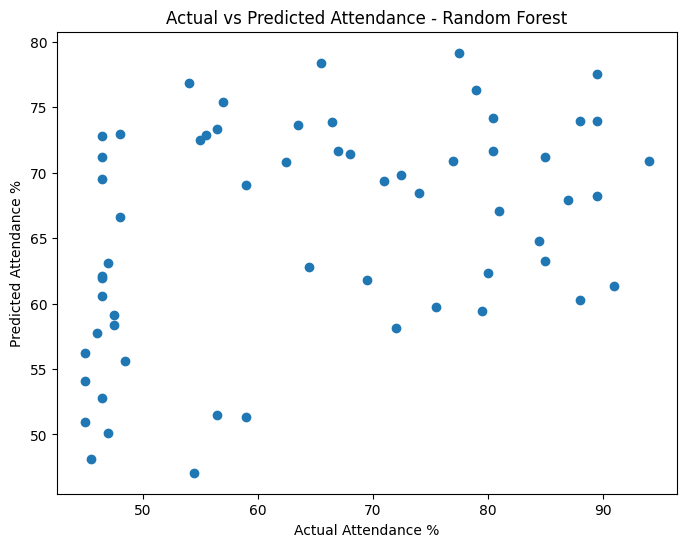

In [142]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions
)

plt.xlabel("Actual Attendance %")
plt.ylabel("Predicted Attendance %")

plt.title(
    f"Actual vs Predicted Attendance - {best_model_name}"
)

plt.show()

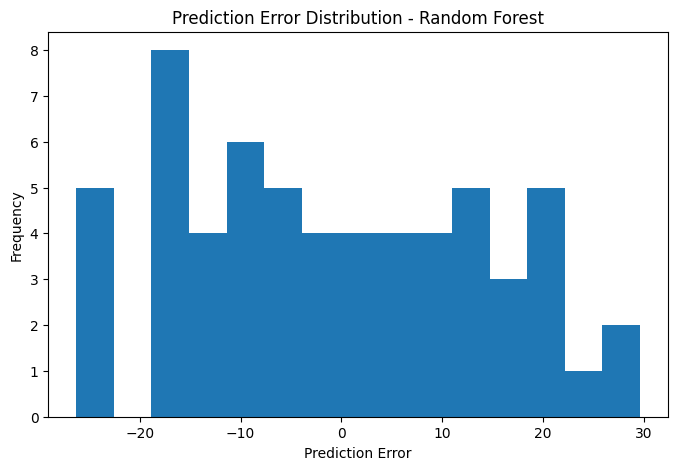

In [143]:
errors = y_test - best_predictions

plt.figure(figsize=(8, 5))

plt.hist(
    errors,
    bins=15
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.title(
    f"Prediction Error Distribution - {best_model_name}"
)

plt.show()

In [144]:
import os

os.makedirs(
    "../outputs/results",
    exist_ok=True
)

In [145]:
results_df.to_csv(
    "../outputs/results/model_comparison.csv",
    index=False
)

In [146]:
results_df.to_csv(
    "../outputs/results/model_comparison.csv",
    index=False
)

In [147]:
joblib.dump(
    best_model,
    "../models/best_model.pkl"
)

print(
    "Best model saved successfully."
)

Best model saved successfully.


In [148]:
feature_information = {
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "target": "Attendance %"
}

print(feature_information)

{'categorical_features': ['Day', 'Subject', 'Faculty ID', 'Branch', 'Section', 'Classroom', 'Practical/Theory', 'Test Week', 'Assignment Due', 'Holiday', 'Weather', 'Special Event', 'Lecture Occurred'], 'numerical_features': ['Lecture Number', 'Semester', 'Total Enrolled Students', 'Previous Lecture Attendance', 'Faculty Experience Years', 'Previous Attendance Missing', 'Start Hour', 'Day of Semester', 'Week Number', 'Rolling 3 Lecture Attendance'], 'target': 'Attendance %'}


In [149]:
import json

with open(
    "../models/feature_information.json",
    "w"
) as f:
    json.dump(
        feature_information,
        f,
        indent=4
    )

# 10. Conclusion

Four regression algorithms were trained to predict classroom
attendance percentage:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor

The models were evaluated using MAE, RMSE, MAPE and R².

The model with the strongest overall performance according to
the evaluation results was selected as the final model.

The selected model was saved for use in the Streamlit deployment
application.